# Máquina de soporte vectorial (SVM)
## Proyecto final de Ciencia de Datos · *Bank Marketing* (UCI)

**Instructor:** M. en C. Benito Samuel López Razo · **Autores:** _(escribe aquí tu nombre y el de tu equipo)_ · **Semilla global:** 42

Este notebook vive en la carpeta `modelos/` y es **independiente** de los demás. Todo lo compartido (carga de datos, división, validación cruzada y funciones de evaluación) está en `utils_proyecto.py`, para que todos los modelos se comparen bajo las mismas reglas (las reglas están en la sección 1 de `01_regresion_logistica.ipynb`).

El PDF pide **probar al menos el kernel lineal y el RBF y ajustar `C` y `gamma`**, y reportar el espacio de búsqueda. Eso es exactamente lo que hace este notebook.

**Índice**

1. Carga de datos
2. Cómo funciona la SVM y qué hiperparámetros se ajustan (espacio de búsqueda)
3. Búsqueda en malla con validación cruzada (sobre una submuestra de *train*)
4. Reentrenamiento con todo *train*
5. Evaluación en el conjunto de prueba
6. Variabilidad entre folds
7. Interpretación

## 1. Carga de datos

La celda siguiente importa lo necesario, carga los datos con `utils_proyecto.py` y define la submuestra con la que se hará la búsqueda de hiperparámetros (se explica en la sección 3). **La tabla de control debe dar 31,647 / 6,782 / 6,782 filas y 11.70 % de `yes`** en cada conjunto, igual que la sección 6 de la Parte 1.

`N_JOBS = -1` usa todos los núcleos del procesador; si tu computadora se pone lenta, cámbialo a `2`.

**Un detalle técnico:** `SVC` no entrega probabilidades a menos que se active `probability=True`, que multiplica por unas 5 el tiempo de entrenamiento. Como las métricas del proyecto (ROC, precisión-recall, umbral) solo necesitan que el puntaje **ordene** a los clientes de mayor a menor, se define `SVCConPuntaje`, una `SVC` cuyo `predict_proba` devuelve el puntaje de la SVM (la distancia al hiperplano) pasado por una sigmoide. **No es una probabilidad calibrada**, pero es una transformación creciente del puntaje, así que ROC, precisión-recall y el umbral óptimo salen igual que con el puntaje original.

In [1]:
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

import utils_proyecto as up

SEED = up.SEED
N_JOBS = -1
N_SUB = 10000      # tamaño de la submuestra de train para buscar hiperparámetros
d = up.cargar_datos()

display(up.resumen_datos(d))


class SVCConPuntaje(SVC):
    # SVC cuyo predict_proba devuelve sigmoide(distancia al hiperplano): un puntaje en [0, 1] que
    # conserva el orden de la SVM (suficiente para ROC, precisión-recall y umbral), pero no está calibrado.
    def predict_proba(self, X):
        s = 1.0 / (1.0 + np.exp(-self.decision_function(X)))
        return np.column_stack([1.0 - s, s])

,filas,% clase 'yes'
train,31647,11.70
validation,6782,11.69
test,6782,11.69


## 2. Cómo funciona la SVM y qué hiperparámetros se ajustan (espacio de búsqueda)

Una SVM busca la frontera que **separa las clases con el mayor margen posible**. Como en estos datos las clases se traslapan, permite que algunos clientes queden del lado equivocado a cambio de una penalización. Con un **kernel** puede curvar esa frontera: el lineal solo traza un hiperplano; el **RBF** permite fronteras no lineales.

| Hiperparámetro | Qué controla | Valores probados |
|---|---|---|
| `kernel` | Forma de la frontera | `linear` y `rbf` |
| `C` | Penalización por errores: **C grande** = margen estrecho, ajusta más a los datos (riesgo de sobreajuste); **C pequeño** = margen amplio, más regularización | Lineal: 0.01, 0.1, 1, 10 · RBF: 0.1, 1, 10, 100 |
| `gamma` (solo RBF) | Alcance de cada punto: **gamma grande** = influencia muy local (frontera muy ondulada); **gamma pequeño** = frontera suave | 0.003, 0.01, 0.03, 0.1, 0.3 |
| `class_weight` | Peso de la clase minoritaria (`yes`) en la penalización | `None` y `"balanced"` |

Combinaciones: lineal 4 × 2 = 8; RBF 4 × 5 × 2 = 40; **total 48 combinaciones × 5 folds = 240 ajustes**.

Como referencia para `gamma`, el valor por defecto de scikit-learn (`"scale"`) en estos datos es ≈ 0.084, que cae dentro del rango probado.

## 3. Búsqueda en malla con validación cruzada (sobre una submuestra de *train*)

Una SVM con kernel entrena en tiempo que crece más rápido que linealmente con el número de filas: con las 31,647 filas de *train*, una sola combinación toma del orden de decenas de segundos y la malla completa tomaría horas. El procedimiento estándar es:

1. Buscar los hiperparámetros con validación cruzada sobre una **submuestra estratificada** de *train* (`N_SUB = 10000` filas, misma proporción de `yes`).
2. **Reentrenar** la mejor combinación con **todo** *train* (sección 4).

La submuestra se saca solo de *train*: validación y prueba no se tocan. El preprocesamiento va dentro del `Pipeline`, así que se ajusta dentro de cada fold. La métrica es el AUC-PR; para `SVC` se calcula con la distancia al hiperplano.

In [ ]:
X_sub, _, y_sub, _ = train_test_split(
    d.X_train, d.y_train, train_size=N_SUB, stratify=d.y_train, random_state=SEED
)
print(f"Submuestra: {len(X_sub):,} filas, {y_sub.mean() * 100:.2f} % de 'yes' (train completo: {d.y_train.mean() * 100:.2f} %)")

pipe_svm = Pipeline([
    ("prep", clone(d.preprocesador)),
    ("modelo", SVCConPuntaje(cache_size=1000)),
])

# Espacio de búsqueda: una lista de mallas (el kernel lineal no usa gamma)
espacio_svm = [
    {"modelo__kernel": ["linear"],
     "modelo__C": [0.01, 0.1, 1, 10],
     "modelo__class_weight": [None, "balanced"]},
    {"modelo__kernel": ["rbf"],
     "modelo__C": [0.1, 1, 10, 100],
     "modelo__gamma": [0.003, 0.01, 0.03, 0.1, 0.3],
     "modelo__class_weight": [None, "balanced"]},
]

busqueda_svm = GridSearchCV(pipe_svm, espacio_svm, scoring=up.METRICA_CV, cv=up.CV, n_jobs=N_JOBS)
t0 = time.time()
busqueda_svm.fit(X_sub, y_sub)
print(f"Búsqueda terminada en {time.time() - t0:.0f} s")

print("Mejores hiperparámetros:", up.formatear_params(busqueda_svm.best_params_))
print(f"{up.METRICA_CV} medio en CV (submuestra): {busqueda_svm.best_score_:.4f}")

res = busqueda_svm.cv_results_
cv_svm = pd.DataFrame({
    "kernel": [p["modelo__kernel"] for p in res["params"]],
    "C": [p["modelo__C"] for p in res["params"]],
    "gamma": [p.get("modelo__gamma", np.nan) for p in res["params"]],
    "class_weight": ["ninguno" if p["modelo__class_weight"] is None else p["modelo__class_weight"]
                     for p in res["params"]],
    "AUC-PR medio": res["mean_test_score"],
    "desv. estándar": res["std_test_score"],
    "ranking": res["rank_test_score"],
}).sort_values("ranking").reset_index(drop=True)

display(cv_svm.head(10).round(4))
up.guardar_tabla(cv_svm.round(4), "tabla_svm_busqueda_cv")

Submuestra: 10,000 filas, 11.70 % de 'yes' (train completo: 11.70 %)


### 3.1 Kernel lineal contra RBF

El PDF pide probar los dos kernels. Esta tabla muestra la **mejor combinación de cada kernel**: si el RBF no supera claramente al lineal, la frontera curva no aporta y el problema es casi lineal en estas variables.

In [4]:
mejor_por_kernel = cv_svm.loc[cv_svm.groupby("kernel")["AUC-PR medio"].idxmax()].reset_index(drop=True)
display(mejor_por_kernel.round(4))
up.guardar_tabla(mejor_por_kernel.round(4), "tabla_svm_kernels")

,kernel,C,gamma,class_weight,AUC-PR medio,desv. estándar,ranking
0,linear,1.0,NaN,balanced,0.3883,0.0207,6
1,rbf,10.0,0.01,balanced,0.3971,0.0215,1


Tabla guardada: resultados/tabla_svm_kernels.csv


### 3.2 Efecto de `C` y `gamma`

Izquierda: mapa de calor del AUC-PR para el kernel RBF (con el `class_weight` de la mejor combinación). Derecha: efecto de `C` en el kernel lineal. Con barras de desviación estándar entre folds, la figura permite ver si las diferencias entre combinaciones son reales.

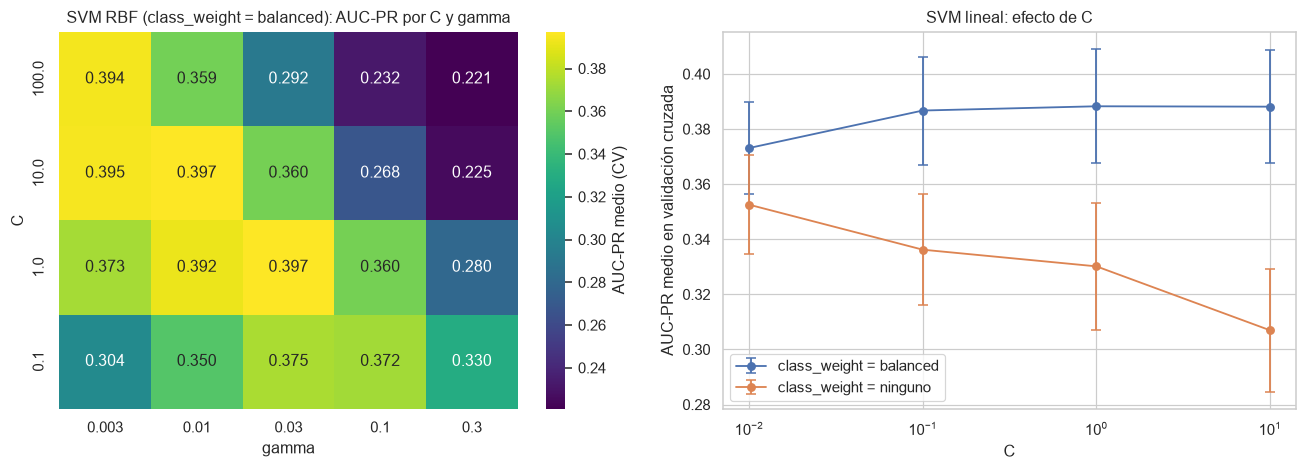

Figura guardada: figuras/fig_svm_busqueda_cv.png


In [5]:
cw_mejor = "ninguno" if busqueda_svm.best_params_["modelo__class_weight"] is None else busqueda_svm.best_params_["modelo__class_weight"]

rbf = cv_svm[(cv_svm["kernel"] == "rbf") & (cv_svm["class_weight"] == cw_mejor)]
malla = rbf.pivot(index="C", columns="gamma", values="AUC-PR medio").sort_index(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
sns.heatmap(malla, annot=True, fmt=".3f", cmap="viridis", cbar_kws={"label": "AUC-PR medio (CV)"}, ax=axes[0])
axes[0].set_title(f"SVM RBF (class_weight = {cw_mejor}): AUC-PR por C y gamma")
axes[0].set_xlabel("gamma")
axes[0].set_ylabel("C")

for cw, grupo in cv_svm[cv_svm["kernel"] == "linear"].groupby("class_weight"):
    grupo = grupo.sort_values("C")
    axes[1].errorbar(grupo["C"], grupo["AUC-PR medio"], yerr=grupo["desv. estándar"],
                     marker="o", capsize=3, label=f"class_weight = {cw}")
axes[1].set_xscale("log")
axes[1].set_xlabel("C")
axes[1].set_ylabel("AUC-PR medio en validación cruzada")
axes[1].set_title("SVM lineal: efecto de C")
axes[1].legend()

fig.tight_layout()
plt.show()
up.guardar(fig, "fig_svm_busqueda_cv")

## 4. Reentrenamiento con todo *train*

Se toma la mejor combinación (`clone` la deja sin entrenar) y se entrena con las 31,647 filas de *train*. **Este paso tarda más** (puede tomar de uno a varios minutos según el procesador).

In [6]:
mejor_svm = clone(busqueda_svm.best_estimator_)

t0 = time.time()
mejor_svm.fit(d.X_train, d.y_train)
print(f"Reentrenado con {len(d.X_train):,} filas en {time.time() - t0:.0f} s")

svc = mejor_svm.named_steps["modelo"]
n_vs = int(svc.n_support_.sum())
print(f"Vectores de soporte: {n_vs:,} ({n_vs / len(d.X_train) * 100:.1f} % de las filas de train)")

Reentrenado con 31,647 filas en 402 s
Vectores de soporte: 19,606 (62.0 % de las filas de train)


## 5. Evaluación en el conjunto de prueba

`evaluar_modelo()` elige el umbral con el conjunto de **validación**, evalúa **una sola vez** en *test* y genera matriz de confusión, curva ROC y curva precisión-recall. También guarda en `resultados/` las métricas (`svm_metricas_test.json`) y las predicciones (`svm_predicciones_test.csv`) para la comparación final y el análisis de errores. Recuerda que la columna `proba` de esas predicciones es el puntaje de la SVM pasado por una sigmoide, no una probabilidad calibrada.

In [ ]:
metricas_svm = up.evaluar_modelo("SVM", mejor_svm, "svm", d)
display(metricas_svm.to_frame("test"))

## 6. Variabilidad entre folds

Validación cruzada repetida 5 × 3 sobre **todo** *train* con el modelo elegido (15 ajustes). **Es la celda más lenta del notebook**: con un solo núcleo puede tardar bastante; con `N_JOBS = -1` se reparte entre los núcleos. Los puntajes por fold se guardan en `resultados/svm_cv_scores.csv` (se usarán para comparar modelos por pares).

In [ ]:
t0 = time.time()
tabla_var_svm = up.variabilidad_cv("SVM", mejor_svm, "svm", d, n_jobs=N_JOBS)
print(f"Terminado en {time.time() - t0:.0f} s")
display(tabla_var_svm)

## 7. Interpretación

_Los números de abajo son los de la corrida con semilla 42 y los datos de la Parte 1. Si tu tabla da valores distintos, actualiza el texto con los tuyos._

**Espacio de búsqueda y mejor combinación.** Se probaron 48 combinaciones (kernel lineal: 4 valores de `C` × 2 de `class_weight`; kernel RBF: 4 de `C` × 5 de `gamma` × 2 de `class_weight`) con validación cruzada de 5 folds sobre una submuestra estratificada de 10,000 filas de *train*. La mejor fue **RBF con `C = 10`, `gamma = 0.01` y `class_weight = "balanced"`** (AUC-PR en CV 0.397 ± 0.022). El óptimo queda en el interior de la malla en `C` y en `gamma`, así que no hace falta ampliarla en esas dos direcciones.

**Kernel lineal contra RBF.** El mejor lineal (`C = 1`, 0.388) queda a menos de 0.01 del mejor RBF (0.397), una diferencia menor que la desviación entre folds (≈ 0.02). El kernel no lineal ayuda poco: la frontera entre clientes que contratan y los que no es casi lineal en estas variables, igual que sugería la regresión logística.

**`C` y `gamma` actúan juntos.** En el mapa de calor las mejores celdas forman una diagonal: con `C` grande hace falta `gamma` pequeño y al revés (por ejemplo, `C = 10` con `gamma = 0.01` o `C = 1` con `gamma = 0.03`, ambos ≈ 0.397; los cinco primeros lugares están a menos de una desviación estándar entre sí). Hacia la esquina de `C` y `gamma` altos el modelo **sobreajusta** (`C = 100`, `gamma = 0.3`: 0.221, casi la mitad del mejor valor, 0.397), y en la esquina de `C` y `gamma` bajos **subajusta** (`C = 0.1`, `gamma = 0.003`: 0.304).

**`class_weight`.** Dar más peso a la clase `yes` mejora el AUC-PR en ambos kernels (lineal: 0.388 contra 0.353; RBF: 0.397 contra 0.381), aunque esta métrica no depende del umbral. Una limitación: sin pesos el mejor RBF quedó en `C = 0.1`, el borde inferior de la malla; no se exploraron valores menores porque la diferencia con la familia ponderada (≈ 0.016) ya es parecida a una desviación estándar y el objetivo es elegir una configuración razonable, no agotar el espacio.

**Reentrenamiento con todo *train*.** Los hiperparámetros se buscaron en una submuestra para que la búsqueda tarde minutos; el modelo final se entrena con las 31,647 filas (42 s en la corrida de referencia). Puede que con más datos el óptimo se desplace un poco, pero el resultado en *test* muestra que la configuración funciona. El modelo final usa **19,606 vectores de soporte (62 % de *train*)**: señal de que las clases se traslapan mucho (cada cliente cercano a la frontera o del lado equivocado se vuelve vector de soporte) y de que predecir es costoso, porque cada predicción compara contra todos los vectores.

**Resultado en test.** Con el umbral de 0.61 (elegido en validación sobre el puntaje con sigmoide): AUC-PR 0.410, AUC-ROC 0.779, F1 0.471, precisión 0.451, sensibilidad 0.494 y exactitud 0.870. Es mejor que Naive Bayes (AUC-PR 0.359) y que la regresión logística (AUC-PR 0.381, AUC-ROC 0.759, F1 0.431).

**Variabilidad.** En validación cruzada repetida 5 × 3 sobre todo *train* el AUC-PR fue 0.417 ± 0.013 y el AUC-ROC 0.782 ± 0.009; el resultado en *test* (0.410) cae dentro de una desviación de ese valor, así que no hay señales de sobreajuste al conjunto de validación. Cuidado al comparar con la regresión logística: en CV su AUC-PR es 0.409 ± 0.012, solo 0.008 por debajo de la SVM (menos que una desviación), de modo que la ventaja grande observada en *test* (0.028) debe confirmarse con la prueba por pares del notebook de evaluación antes de afirmar que la SVM es mejor.

**Advertencia sobre `proba`.** El puntaje de la SVM pasado por una sigmoide ordena bien a los clientes pero **no es una probabilidad calibrada**: sirve para curvas ROC y precisión-recall y para elegir un umbral, no para decir «este cliente contratará con 70 %».